<a href="https://colab.research.google.com/github/shahriarshadhin3-alt/uterine-emg-preterm-detection/blob/main/notebooks/01_dataset_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 01 - TPEHG Dataset Exploration

## Project
Uterine EMG Analysis for Preterm Birth Detection

## Objective
To explore the Term-Preterm ElectroHysterogram (TPEHG) Database from PhysioNet.

## Dataset Information
- Total records: 300
- Term: 262
- Preterm: 38
- Sampling frequency: 20 Hz
- Recording duration: 30 minutes
- Physical EHG channels: 3

## Main Tasks
1. Access the dataset.
2. Read recording information.
3. Explore pregnancy labels.
4. Load an EHG recording.
5. Visualize the raw signal.

In [3]:

# Install missing biomedical signal processing libraries

!pip install wfdb PyWavelets


In [4]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import requests

# Dataset information

dataset_url = "https://physionet.org/files/tpehgdb/1.0.1/"

# Sampling frequency
fs = 20

# Recording duration
duration = 30 * 60

# Expected samples per channel
total_samples = fs * duration

print("Sampling Frequency:", fs, "Hz")
print("Recording Duration:", duration, "seconds")
print("Expected Samples:", total_samples)

print("\nDataset information loaded successfully!")


Sampling Frequency: 20 Hz
Recording Duration: 1800 seconds
Expected Samples: 36000

Dataset information loaded successfully!


In [5]:

# Download and inspect the metadata file

metadata_url = dataset_url + "tpehgdb.smr"

response = requests.get(metadata_url)
response.raise_for_status()

metadata_text = response.text

# Display the first 12 lines
print(metadata_text[:1500])


 Record    | Gestation | Rec. time |   Group   | Premature | Early 
-----------+-----------+-----------+-----------+-----------+------- 
 tpehg1007 |     35.00 |     31.29 | >=26-PRE  | t         | f
 tpehg1021 |     38.57 |     22.29 | <26-TERM  | f         | t
 tpehg1022 |     38.57 |     31.00 | >=26-TERM | f         | f
 tpehg1027 |     37.14 |     31.29 | >=26-TERM | f         | f
 tpehg1029 |     38.57 |     31.00 | >=26-TERM | f         | f
 tpehg1031 |     38.86 |     22.14 | <26-TERM  | f         | t
 tpehg1039 |     40.29 |     22.86 | <26-TERM  | f         | t
 tpehg1065 |     41.29 |     30.29 | >=26-TERM | f         | f
 tpehg1070 |     39.57 |     22.00 | <26-TERM  | f         | t
 tpehg1088 |     41.00 |     22.14 | <26-TERM  | f         | t
 tpehg1089 |     38.86 |     21.86 | <26-TERM  | f         | t
 tpehg1093 |     39.43 |     22.29 | <26-TERM  | f         | t
 tpehg1097 |     39.57 |     24.43 | <26-TERM  | f         | t
 tpehg1113 |     39.71 |     31.00 | >=26-TE

In [7]:

# Read one EHG recording directly from PhysioNet

record = wfdb.rdrecord(
    "tpehg1007",
    pn_dir="tpehgdb/1.0.1/tpehgdb"
)

# Display recording information

print("Sampling Frequency:", record.fs)

print("Signal Shape:", record.p_signal.shape)

print("Number of Signal Channels:", record.n_sig)

print("Signal Names:", record.sig_name)


Sampling Frequency: 20
Signal Shape: (35180, 12)
Number of Signal Channels: 12
Signal Names: ['1', '1_DOCFILT-4-0.08-4', '1_DOCFILT-4-0.3-3', '1_DOCFILT-4-0.3-4', '2', '2_DOCFILT-4-0.08-4', '2_DOCFILT-4-0.3-3', '2_DOCFILT-4-0.3-4', '3', '3_DOCFILT-4-0.08-4', '3_DOCFILT-4-0.3-3', '3_DOCFILT-4-0.3-4']


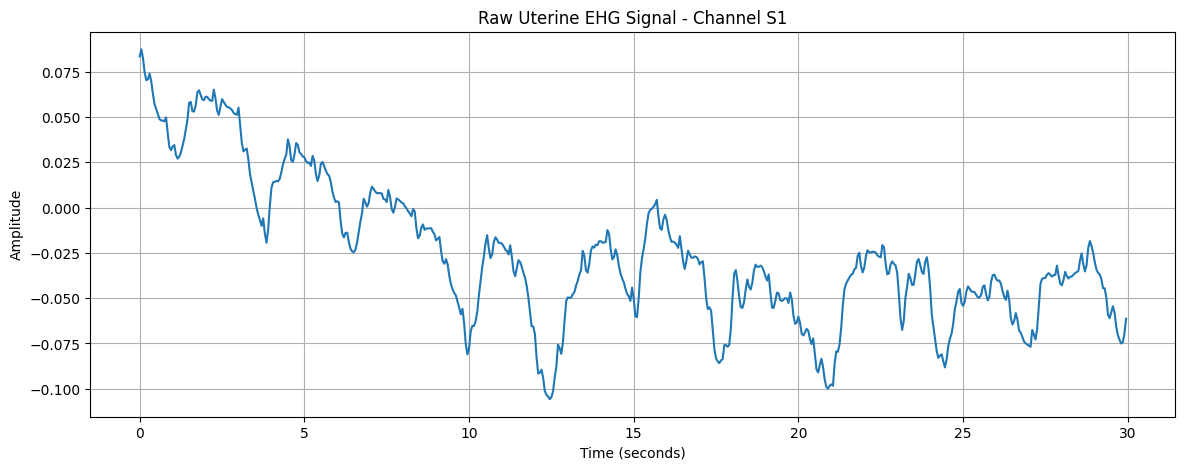

In [8]:

# Extract the first signal channel (S1, unfiltered)

signal = record.p_signal[:, 0]

# Create time axis
time = np.arange(len(signal)) / record.fs

# Plot first 30 seconds
plt.figure(figsize=(14, 5))

plt.plot(time[:600], signal[:600])

plt.title("Raw Uterine EHG Signal - Channel S1")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.grid(True)
plt.show()
